# Watershed Delineation with PyGILE-Plus

## Overview

This notebook demonstrates automated watershed delineation using Digital Elevation Models (DEMs) and WhiteboxTools.

## What is Watershed Delineation?

A watershed, also known as a drainage basin or catchment, is an area where all water drains to a common outlet point called a pour point. Understanding watershed boundaries is critical for hydrology applications such as water flow modeling and flood prediction, environmental studies including pollutant transport and ecosystem boundaries, land use planning to understand drainage patterns, and agriculture for irrigation system design and erosion management.

## The Delineation Process

The watershed delineation workflow involves several steps. First, depressions in the DEM are filled to remove sinks that would trap flow. Next, flow direction is calculated to determine where water flows from each cell. Flow accumulation is then computed to show how much upstream area drains through each cell. From this, a stream network is extracted based on a flow accumulation threshold. A pour point is selected to mark the watershed outlet, and finally, all cells that contribute flow upstream of the pour point are traced to define the watershed boundary.

## Setup and Imports

This cell imports the required Python libraries for watershed delineation.

**Libraries used:**
- `rasterio` and `rasterio.mask`: Reading and clipping raster DEM data
- `geopandas`: Creating and manipulating vector geometries (pour points, watershed boundaries)
- `shapely`: Geometric operations for converting raster to vector
- `folium`: Creating interactive maps for pour point selection
- `pyproj.Transformer`: Converting coordinates between CRS (WGS84 and projected)
- `matplotlib`: Visualizing the watershed results

The cell also loads the configuration from `watershed_analysis.json` created in Notebook 01 and creates the output directories.

In [1]:
import json
import os
import subprocess
import numpy as np
import rasterio
import rasterio.mask
from rasterio.features import shapes
import geopandas as gpd
from shapely.geometry import shape
import matplotlib.pyplot as plt
import folium
from folium.plugins import MousePosition
from pyproj import Transformer
import warnings
warnings.filterwarnings('ignore')

# Load configuration
with open('watershed_analysis.json', 'r') as f:
    config = json.load(f)

# Create output directories
os.makedirs(config["temp_dir"], exist_ok=True)
os.makedirs(config["output_dir"], exist_ok=True)

print("Setup complete")
print(f"DEM: {config['dem_path']}")
print(f"Output: {config['output_dir']}")

Setup complete
DEM: clipped_dem.tif
Output: results


## Watershed Delineation Class

The `WatershedDelineator` class encapsulates the watershed delineation workflow.

Key updates in this notebook:
- one or more pour points can be entered
- each pour point is delineated separately
- extracted streams are exported as a shapefile

If multiple pour points are used, the notebook creates separate outputs for each one using numbered file names.

In [2]:
class WatershedDelineator:
    """
    Automated watershed delineation from DEM data using WhiteboxTools
    """

    def __init__(self, dem_path):
        """Initialize delineator with DEM"""
        self.dem_path = dem_path
        self.temp_dir = config["temp_dir"]

        # Read DEM metadata
        with rasterio.open(dem_path) as src:
            self.cell_size = src.res[0]
            self.crs = src.crs
            bounds = src.bounds

            # Setup coordinate transformers
            self.to_wgs84 = Transformer.from_crs(self.crs, config["target_crs"], always_xy=True)
            self.from_wgs84 = Transformer.from_crs(config["target_crs"], self.crs, always_xy=True)

            # Transform bounds to WGS84
            minx, miny = self.to_wgs84.transform(bounds.left, bounds.bottom)
            maxx, maxy = self.to_wgs84.transform(bounds.right, bounds.top)
            self.bounds_wgs84 = {'minx': minx, 'miny': miny, 'maxx': maxx, 'maxy': maxy}

    def get_pour_points(self):
        """Create interactive map for selecting one or more pour points"""
        center_lat = (self.bounds_wgs84['miny'] + self.bounds_wgs84['maxy']) / 2
        center_lng = (self.bounds_wgs84['minx'] + self.bounds_wgs84['maxx']) / 2

        # Create map
        m = folium.Map(location=[center_lat, center_lng], zoom_start=13)

        # Add DEM boundary
        bounds_coords = [
            [self.bounds_wgs84['miny'], self.bounds_wgs84['minx']],
            [self.bounds_wgs84['miny'], self.bounds_wgs84['maxx']],
            [self.bounds_wgs84['maxy'], self.bounds_wgs84['maxx']],
            [self.bounds_wgs84['maxy'], self.bounds_wgs84['minx']]
        ]
        folium.Polygon(bounds_coords, color='blue', weight=2, fill=True, fillOpacity=0.1).add_to(m)

        MousePosition().add_to(m)
        folium.LatLngPopup().add_to(m)

        # Display map
        try:
            from IPython.display import display
            display(m)
        except ImportError:
            m.save("pour_point_map.html")
            print("Map saved to pour_point_map.html")

        print("Enter one or more pour points.")
        print("Type DONE when you have finished selecting points.")

        pour_points = []

        while True:
            lat_input = input("Enter Latitude (or DONE): ").strip()
            if lat_input.upper() == "DONE":
                if pour_points:
                    return pour_points
                print("At least one pour point is required.")
                continue

            lng_input = input("Enter Longitude: ").strip()

            try:
                lat = float(lat_input)
                lng = float(lng_input)

                if (self.bounds_wgs84['miny'] <= lat <= self.bounds_wgs84['maxy'] and 
                    self.bounds_wgs84['minx'] <= lng <= self.bounds_wgs84['maxx']):
                    if input(f"Add Lat={lat:.6f}, Lng={lng:.6f}? (y/n): ").lower() == 'y':
                        pour_points.append((lat, lng))
                        print(f"Added pour point {len(pour_points)}: ({lat:.6f}, {lng:.6f})")
                else:
                    print("Point outside DEM bounds. Try again.")
            except ValueError:
                print("Invalid input. Try again.")

    def delineate_watershed(self, lat, lng, point_id=1, total_points=1):
        """Perform watershed delineation using WhiteboxTools"""
        # Transform pour point to DEM projection
        x_proj, y_proj = self.from_wgs84.transform(lng, lat)

        suffix = f"_{point_id}"

        # Create pour point shapefile
        gdf = gpd.GeoDataFrame(
            {'id': [point_id]}, 
            geometry=gpd.points_from_xy([x_proj], [y_proj]), 
            crs=self.crs
        )
        pour_point_path = os.path.join(self.temp_dir, f'pour_point{suffix}.shp')
        gdf.to_file(pour_point_path)

        # Copy DEM to temp directory
        import shutil
        dem_temp = os.path.join(self.temp_dir, f'dem{suffix}.tif')
        shutil.copy2(self.dem_path, dem_temp)

        dem_filled = os.path.join(self.temp_dir, f'dem_filled{suffix}.tif')
        d8_pointer = os.path.join(self.temp_dir, f'd8_pointer{suffix}.tif')
        flow_accum = os.path.join(self.temp_dir, f'flow_accum{suffix}.tif')
        pour_point_snapped = os.path.join(self.temp_dir, f'pour_point_snapped{suffix}.shp')
        watershed_raster = os.path.join(self.temp_dir, f'watershed{suffix}.tif')

        print("\nStep 1: Filling depressions...")
        self._run_whitebox('FillDepressions', {
            'dem': dem_temp,
            'output': dem_filled,
            'fix_flats': 'true'
        })

        print("Step 2: Calculating D8 flow pointer...")
        self._run_whitebox('D8Pointer', {
            'dem': dem_filled,
            'output': d8_pointer
        })

        print("Step 3: Calculating flow accumulation...")
        self._run_whitebox('D8FlowAccumulation', {
            'input': d8_pointer,
            'output': flow_accum,
            'pntr': 'true'
        })

        print("Step 4: Snapping pour point to high-flow cells...")
        snap_distance = self.cell_size * 10
        self._run_whitebox('SnapPourPoints', {
            'pour_pts': pour_point_path,
            'flow_accum': flow_accum,
            'output': pour_point_snapped,
            'snap_dist': snap_distance
        })

        print("Step 5: Delineating watershed...")
        self._run_whitebox('Watershed', {
            'd8_pntr': d8_pointer,
            'pour_pts': pour_point_snapped,
            'output': watershed_raster
        })

        print("Step 6: Converting watershed to vector...")
        watershed_vector = self._raster_to_vector(watershed_raster, suffix)

        print("Step 7: Clipping DEM to watershed...")
        clipped_dem = self._clip_dem_with_watershed(watershed_vector, suffix)

        return watershed_vector, clipped_dem

    def _run_whitebox(self, tool_name, parameters):
        """Execute WhiteboxTools command"""
        cmd = [config['whitebox_tools'], f'--run={tool_name}']
        for key, value in parameters.items():
            cmd.append(f'--{key}={value}')
        cmd.append('--verbose=false')

        result = subprocess.run(cmd, capture_output=True, text=True)
        if result.returncode != 0:
            raise Exception(f"WhiteboxTools {tool_name} failed: {result.stderr}")

    def _raster_to_vector(self, watershed_raster, suffix=""):
        """Convert watershed raster to vector polygon"""
        with rasterio.open(watershed_raster) as src:
            data = src.read(1)
            transform = src.transform
            crs = src.crs

        # Vectorize
        polygons = []
        for geom, value in shapes(data.astype(np.int32), mask=data > 0, transform=transform):
            if value > 0:
                polygons.append(shape(geom))

        if polygons:
            gdf = gpd.GeoDataFrame({'id': range(len(polygons))}, geometry=polygons, crs=crs)
            vector_path = os.path.join(config['output_dir'], f'watershed{suffix}.shp')
            gdf.to_file(vector_path)

            # Maintain legacy output name for downstream cells when multiple pour points are used
            if suffix:
                legacy_path = os.path.join(config['output_dir'], 'watershed.shp')
                for ext in ['.shp', '.shx', '.dbf', '.prj', '.cpg']:
                    src_file = vector_path.replace('.shp', ext)
                    if os.path.exists(src_file):
                        shutil.copy2(src_file, legacy_path.replace('.shp', ext))
            return vector_path
        return None


    def _clip_dem_with_watershed(self, watershed_vector, suffix=""):
        """Clip DEM to watershed boundary with proper NoData handling"""
        if not watershed_vector:
            return None

        watershed_gdf = gpd.read_file(watershed_vector)

        with rasterio.open(self.dem_path) as src:
            # Define a proper NoData value for elevation data
            nodata_value = -9999.0

            # Mask with explicit nodata fill value
            out_image, out_transform = rasterio.mask.mask(
                src, 
                watershed_gdf.geometry, 
                crop=True,
                nodata=nodata_value,
                filled=True
            )

            out_meta = src.meta.copy()
            out_meta.update({
                "driver": "GTiff",
                "height": out_image.shape[1],
                "width": out_image.shape[2],
                "transform": out_transform,
                "nodata": nodata_value,
                "dtype": "float32"
            })

            # Convert to float32 if needed
            out_image = out_image.astype(np.float32)

            clipped_dem_path = os.path.join(config['output_dir'], f'watershed_dem{suffix}.tif')
            with rasterio.open(clipped_dem_path, "w", **out_meta) as dest:
                dest.write(out_image)

            # Maintain legacy output name for downstream cells when multiple pour points are used
            if suffix:
                legacy_path = os.path.join(config['output_dir'], 'watershed_dem.tif')
                shutil.copy2(clipped_dem_path, legacy_path)

            print(f"  NoData value set to: {nodata_value}")

            return clipped_dem_path

    def visualize_results(self, watershed_vector, clipped_dem, lat, lng):
        """Create visualization of results"""
        if not watershed_vector or not clipped_dem:
            return

        x_proj, y_proj = self.from_wgs84.transform(lng, lat)

        # Read original DEM
        with rasterio.open(self.dem_path) as src:
            original_dem = src.read(1, masked=True)
            original_extent = [src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top]

        # Read clipped DEM
        with rasterio.open(clipped_dem) as src:
            clipped_data = src.read(1, masked=True)
            clipped_extent = [src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top]

        # Read watershed and calculate area
        watershed_gdf = gpd.read_file(watershed_vector)
        area_km2 = watershed_gdf.geometry.area.sum() / 1e6

        # Create figure
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

        # Left: Original DEM with watershed
        im1 = ax1.imshow(original_dem, extent=original_extent, cmap='terrain', aspect='equal')
        watershed_gdf.plot(ax=ax1, facecolor='none', edgecolor='red', linewidth=2.5)
        ax1.scatter(x_proj, y_proj, c='red', s=200, marker='o', edgecolor='white', linewidth=2)
        ax1.set_title(f'Original DEM with Watershed Boundary', 
                     fontsize=14, fontweight='bold', pad=15)
        ax1.set_xlabel('Easting (m)', fontsize=11)
        ax1.set_ylabel('Northing (m)', fontsize=11)
        ax1.ticklabel_format(style='plain', useOffset=False)
        plt.setp(ax1.get_xticklabels(), rotation=30, ha='right', fontsize=9)
        plt.setp(ax1.get_yticklabels(), fontsize=9)
        ax1.grid(True, alpha=0.3)

        cbar1 = plt.colorbar(im1, ax=ax1, shrink=0.7, pad=0.02)
        cbar1.set_label('Elevation (m)', fontsize=11)

        # Right: Clipped DEM
        im2 = ax2.imshow(clipped_data, extent=clipped_extent, cmap='terrain', aspect='equal')
        ax2.scatter(x_proj, y_proj, c='red', s=200, marker='o', edgecolor='white', linewidth=2)
        ax2.set_title('Watershed DEM (Clipped)', fontsize=14, fontweight='bold', pad=15)
        ax2.set_xlabel('Easting (m)', fontsize=11)
        ax2.set_ylabel('Northing (m)', fontsize=11)
        ax2.ticklabel_format(style='plain', useOffset=False)
        plt.setp(ax2.get_xticklabels(), rotation=30, ha='right', fontsize=9)
        plt.setp(ax2.get_yticklabels(), fontsize=9)
        ax2.grid(True, alpha=0.3)

        cbar2 = plt.colorbar(im2, ax=ax2, shrink=0.7, pad=0.02)
        cbar2.set_label('Elevation (m)', fontsize=11)

        plt.tight_layout()
        viz_path = os.path.join(config["output_dir"], 'watershed_results.png')
        plt.savefig(viz_path, dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()

        print(f"\nVisualization saved to: {viz_path}")
        print(f"Watershed area: {area_km2:.2f} km²")
        return viz_path

print("WatershedDelineator class loaded")

WatershedDelineator class loaded


## Run Watershed Delineation

This cell executes the delineation workflow.

Workflow:
1. Create a `WatershedDelineator` instance
2. Display an interactive map for pour point selection
3. Enter one or more pour points
4. Type `DONE` when finished
5. Run watershed delineation separately for each pour point
6. Save watershed and stream outputs for each result

Outputs saved to the results directory:
- `watershed.shp` or `watershed_1.shp`, `watershed_2.shp`, ...
- `streams.shp` or `streams_1.shp`, `streams_2.shp`, ...
- `watershed_dem.tif` or `watershed_dem_1.tif`, `watershed_dem_2.tif`, ...
- `watershed_results.png`

How to select pour points:
- click on the map to inspect coordinates
- enter latitude and longitude values
- repeat for as many pour points as needed
- type `DONE` when finished
- each pour point is snapped to the nearest stream cell before delineation

Please select one or more pour points on the interactive map...


Enter one or more pour points.
Type DONE when you have finished selecting points.


Enter Latitude (or DONE):  27.8328
Enter Longitude:  85.5744
Add Lat=27.832800, Lng=85.574400? (y/n):  y


Added pour point 1: (27.832800, 85.574400)


Enter Latitude (or DONE):  done



Delineating watershed 1 of 1 for pour point: (27.832800, 85.574400)


Step 1: Filling depressions...
Step 2: Calculating D8 flow pointer...
Step 3: Calculating flow accumulation...
Step 4: Snapping pour point to high-flow cells...
Step 5: Delineating watershed...
Step 6: Converting watershed to vector...


Warning 1: DeprecationWarning: 'Memory' driver is deprecated since GDAL 3.11. Use 'MEM' onwards. Further messages of this type will be suppressed.


Step 7: Clipping DEM to watershed...
  NoData value set to: -9999.0

Watershed delineation 1 successful


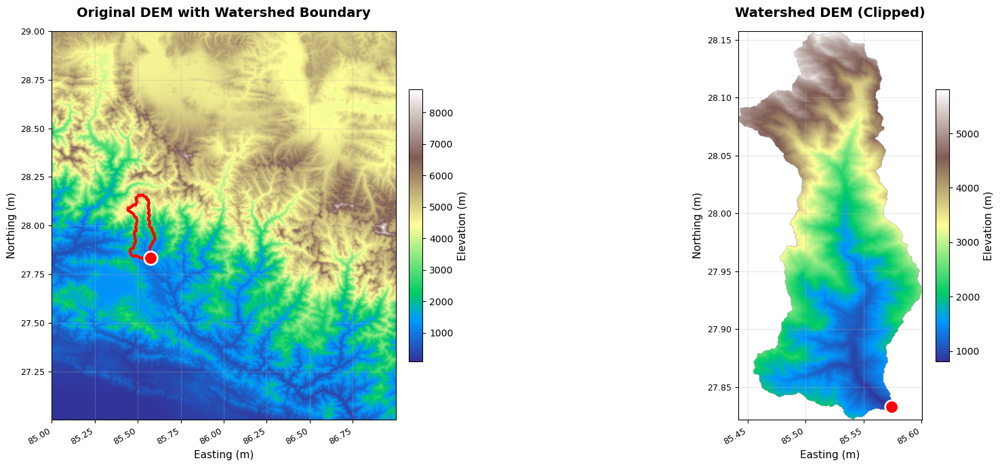


Visualization saved to: results/watershed_results.png
Watershed area: 0.00 km²

Results saved to: results
  - watershed_1.shp: Watershed boundary
  - watershed_dem_1.tif: Clipped DEM
  - watershed_results.png: Visualization

Completed delineation for 1 pour point(s).


In [3]:
import shutil

# Create delineator
delineator = WatershedDelineator(config['dem_path'])

# Get pour points from user
print("Please select one or more pour points on the interactive map...")
pour_points = delineator.get_pour_points()

results = []

for idx, (lat, lng) in enumerate(pour_points, start=1):
    print(f"\nDelineating watershed {idx} of {len(pour_points)} for pour point: ({lat:.6f}, {lng:.6f})\n")
    watershed_vector, clipped_dem = delineator.delineate_watershed(
        lat, lng, point_id=idx, total_points=len(pour_points)
    )

    if watershed_vector and clipped_dem:
        print(f"\nWatershed delineation {idx} successful")
        delineator.visualize_results(watershed_vector, clipped_dem, lat, lng)
        results.append({
            "point_id": idx,
            "lat": lat,
            "lng": lng,
            "watershed_vector": watershed_vector,
            "clipped_dem": clipped_dem
        })
        print(f"\nResults saved to: {config['output_dir']}")
        print(f"  - {os.path.basename(watershed_vector)}: Watershed boundary")
        print(f"  - {os.path.basename(clipped_dem)}: Clipped DEM")
        print("  - watershed_results.png: Visualization")
    else:
        print(f"\nWatershed delineation {idx} failed")

if results:
    print(f"\nCompleted delineation for {len(results)} pour point(s).")
else:
    print("\nWatershed delineation failed.")

## 3D Terrain Visualization

This cell creates an interactive 3D surface plot of the delineated watershed using Plotly.

**Processing steps:**
1. Reads the clipped watershed DEM (`watershed_dem.tif`)
2. Masks NoData values (set to -9999) as NaN so they appear as gaps
3. Downsamples large DEMs to 500x500 for performance
4. Creates a `go.Surface` plot with earth colorscale

**Plotly features:**
- `connectgaps=False`: Preserves the watershed boundary shape by not interpolating across NoData
- Custom lighting for realistic terrain shading
- Interactive rotation, zoom, and pan
- Aspect ratio adjusted to reduce vertical exaggeration

You can rotate the 3D view by clicking and dragging, zoom with scroll wheel, and pan with right-click drag.

Original DEM size: (1210, 572)
Resampled DEM size: (605, 286)
Elevation range: 809.5 - 5807.3 m


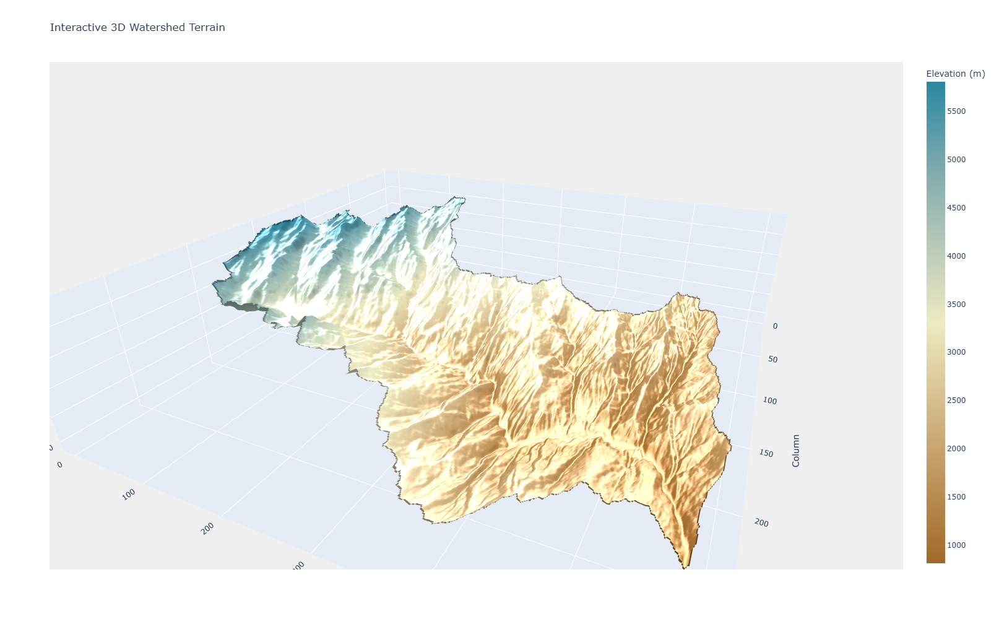

3D visualization created.


In [4]:
import plotly.graph_objects as go
import numpy as np
from scipy.ndimage import zoom

point_id = 1  # choose which watershed to visualize
clipped_dem_path = os.path.join(config['output_dir'], f'watershed_dem_{point_id}.tif')

with rasterio.open(clipped_dem_path) as src:
    elevation = src.read(1).astype(float)
    nodata = src.nodata
    
    # Mask NoData values as NaN
    if nodata is not None:
        elevation[elevation == nodata] = np.nan
    
    # Mask extreme values
    elevation[elevation < -1000] = np.nan
    elevation[elevation > 9000] = np.nan

# Downsample using simple slicing (preserves NaN better than zoom)
target_size = 500
step = max(1, max(elevation.shape) // target_size)
elevation_resampled = elevation[::step, ::step]

height, width = elevation_resampled.shape
x = np.arange(width)
y = np.arange(height)

print(f"Original DEM size: {elevation.shape}")
print(f"Resampled DEM size: {elevation_resampled.shape}")
print(f"Elevation range: {np.nanmin(elevation_resampled):.1f} - {np.nanmax(elevation_resampled):.1f} m")

# Create 3D surface plot - Plotly handles NaN as gaps
fig = go.Figure(data=[
    go.Surface(
        z=elevation_resampled,
        x=x,
        y=y,
        colorscale='earth',
        colorbar=dict(title="Elevation (m)"),
        connectgaps=False,  # Don't interpolate across NaN gaps
        lighting=dict(
            ambient=0.6,
            diffuse=0.9,
            specular=0.5,
            roughness=0.5,
            fresnel=0.2
        )
    )
])

fig.update_layout(
    title='Interactive 3D Watershed Terrain',
    scene=dict(
        xaxis_title='Column',
        yaxis_title='Row',
        zaxis_title='Elevation (m)',
        aspectmode='manual',
        aspectratio=dict(x=2, y=2, z=0.5),  # Reduced z exaggeration
        camera=dict(eye=dict(x=1.87, y=0.88, z=1)),
        bgcolor='rgb(240, 240, 240)'
    ),
    width=1500,
    height=1000
)

fig.show()
print("3D visualization created.")

## Summary

This notebook demonstrated automated watershed delineation using WhiteboxTools, interactive pour point selection with Folium maps, a complete hydrological workflow from DEM to watershed boundary, and production of vector and raster outputs ready for further analysis.

## Understanding the Results

The watershed area represents the total drainage area contributing to your pour point. Small watersheds under 10 square kilometers typically show quick response to rainfall events. Medium watersheds between 10 and 1000 square kilometers are useful for regional water resource planning. Large watersheds exceeding 1000 square kilometers represent major river basins.

The watershed boundary shown as a red outline marks the drainage divide, while the pour point shown as a red dot marks the watershed outlet where all water in the watershed eventually flows.

## Applications

The delineated watershed can be used for hydrological modeling including runoff simulation and flood prediction, water quality analysis for pollutant source tracking, land use assessment to analyze impacts on drainage, and conservation planning for ecosystem management.

## Next Steps

The clipped watershed DEM saved as watershed_dem.tif can be used with other notebooks in this series. The SAGA GIS tutorial covers terrain analysis, the GRASS GIS tutorial explores geomorphometry, the OTB tutorial demonstrates image processing, and the WhiteboxTools tutorial provides additional hydrological analysis capabilities.

## References

Lindsay, J.B. (2016). Whitebox GAT: A case study in geomorphometric analysis. Computers and Geosciences, 95, 75-84.

Jenson, S.K., Domingue, J.O. (1988). Extracting topographic structure from digital elevation data. Photogrammetric Engineering and Remote Sensing, 54(11), 1593-1600.